In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris

In [2]:
iris = load_iris()

X = iris.data

y = iris.target

In [3]:
X.shape

(150, 4)

In [4]:
features_names = iris.feature_names

In [5]:
features_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [6]:
from sklearn.preprocessing import StandardScaler

In [7]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [8]:
X_scaled.mean(axis =0)

array([-1.69031455e-15, -1.84297022e-15, -1.69864123e-15, -1.40924309e-15])

In [9]:
X_scaled.std(axis = 0)

array([1., 1., 1., 1.])

In [10]:
from sklearn.decomposition import PCA

In [11]:
pca = PCA(
    n_components=2
)

X_pca = pca.fit_transform(X_scaled)

In [12]:
X_pca.shape

(150, 2)

In [13]:
pca.explained_variance_ratio_

array([0.72962445, 0.22850762])

In [14]:
pca.explained_variance_ratio_.sum()

np.float64(0.9581320720000166)

Text(0.5, 1.0, 'PCA: Iris data reduced to 4D to 2D')

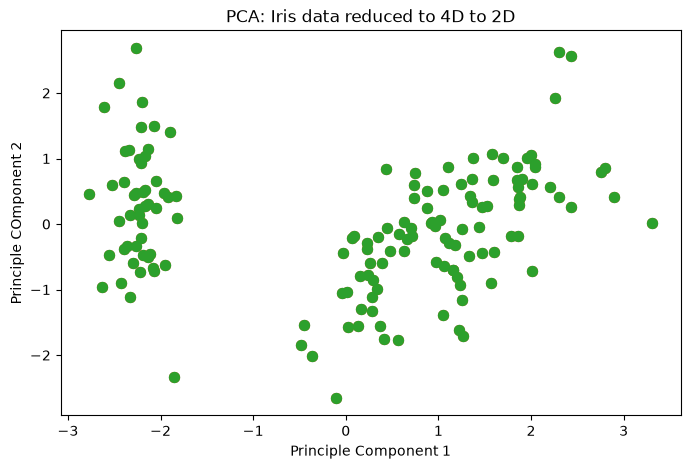

In [17]:
plt.figure(figsize=(8,5))

for class_id, species in enumerate(iris.target_names):
    mask = y == class_id

    plt.scatter(
        X_pca[:,0],
        X_pca[:,1],
        label = species,
        s =50
    )

plt.xlabel("Principle Component 1")
plt.ylabel("Principle COmponent 2")
plt.title("PCA: Iris data reduced to 4D to 2D")

In [18]:
explained_variance = pca.explained_variance_ratio_

cumulative_variance = np.cumsum(explained_variance)

In [19]:
cumulative_variance

array([0.72962445, 0.95813207])

Text(0.5, 1.0, 'Choosing the number of Principle components')

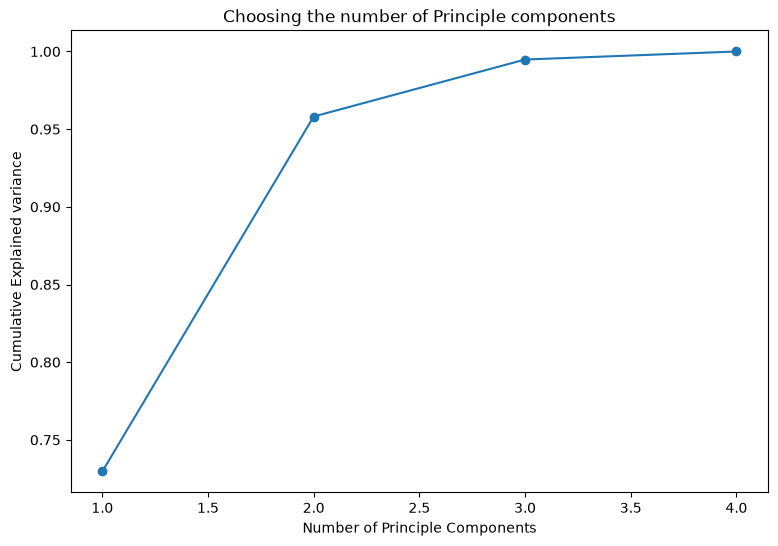

In [21]:
pca_full = PCA()

pca_full.fit(X_scaled)

cumulative = np.cumsum(
    pca_full.explained_variance_ratio_
)

plt.figure(figsize=(9,6))

plt.plot(
    range(1, len(cumulative) + 1),
    cumulative,
    marker = 'o'
)

plt.xlabel("Number of Principle Components")
plt.ylabel("Cumulative Explained variance")
plt.title("Choosing the number of Principle components")